**5.4 ANÁLISIS DE LA VARIABILIDAD DE LA FRECUENCIA CARDÍACA (HRV)**

**Datos:** `ECG_ManuNUEVO1.txt` (1000 muestras del ADC de 10 bits).Periodo de ≈ 10 ms, por lo que **fs ≈ 100 Hz** y el registro dura ≈ 10 s.

In [11]:
# Parche de compatibilidad: hrvanalysis busca LombScargle en astropy.stats,
# pero las versiones recientes de astropy lo tienen en astropy.timeseries
try:
    import astropy.stats
    from astropy.timeseries import LombScargle
    astropy.stats.LombScargle = LombScargle
except ImportError:
    pass

#%pip install neurokit2 py-ecg-detectors hrv-analysis   # solo la primera vez
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.backends   # evita un error de activación del backend gráfico en algunos entornos
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import butter, sosfiltfilt, find_peaks

try:
    import neurokit2 as nk
    HAY_NK = True
except ImportError:
    HAY_NK = False
    print("neurokit2 no está instalado -> pip install neurokit2")

try:
    from ecgdetectors import Detectors
    HAY_DET = True
except ImportError:
    HAY_DET = False
    print("py-ecg-detectors no está instalado -> pip install py-ecg-detectors")

try:
    from hrvanalysis import (get_time_domain_features, remove_outliers,
                             remove_ectopic_beats, interpolate_nan_values)
    HAY_HRV = True
except ImportError as e:
    HAY_HRV = False
    print("hrv-analysis no se pudo importar:", e)

# ---- Parámetros de la adquisición ----
FS = 100                       # Hz. Sale de delay(10) en el código de Arduino
DATA_DIR = Path(".")           # carpeta donde están los .txt
ARCHIVOS = {
    "ECG_ManuNUEVO1": "ECG_ManuNUEVO1.txt",
}

**Carga de la señal**

ECG_ManuNUEVO1: 1000 muestras = 10.0 s | min 401, max 702 (cuentas ADC)


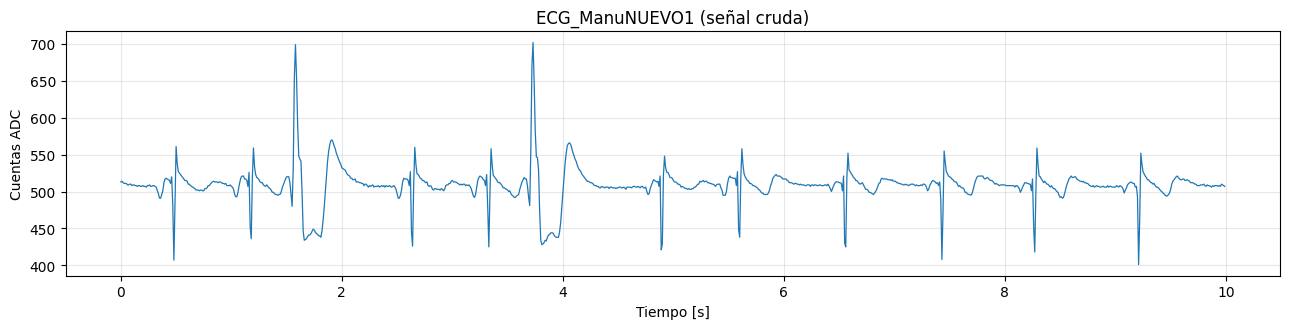

In [12]:
señales = {}
for nombre, archivo in ARCHIVOS.items():
    ruta = DATA_DIR / archivo
    if not ruta.exists():
        raise FileNotFoundError(f"No encuentro {ruta.resolve()}. Pon los .txt junto al notebook o cambia DATA_DIR.")
    señales[nombre] = np.loadtxt(ruta)
    print(f"{nombre}: {len(señales[nombre])} muestras = {len(señales[nombre])/FS:.1f} s | "
          f"min {señales[nombre].min():.0f}, max {señales[nombre].max():.0f} (cuentas ADC)")

fig, ejes = plt.subplots(len(señales), 1, figsize=(13, 3.4*len(señales)), sharex=True, squeeze=False); ejes = ejes[:, 0]
for ax, (nombre, x) in zip(ejes, señales.items()):
    ax.plot(np.arange(len(x))/FS, x, lw=0.9)
    ax.set_title(f"{nombre} (señal cruda)")
    ax.set_ylabel("Cuentas ADC")
    ax.grid(alpha=0.3)
ejes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

**Acondicionamiento y referencia manual.** Se resta la mediana y se aplica un pasa-altas Butterworth de 0.5 Hz contra la deriva de línea base; no se aplica filtro de 50/60 Hz porque con fs = 100 Hz el límite de Nyquist es 50 Hz. Para decidir qué algoritmo detecta mejor se anotó a mano la posición de cada latido (12 latidos, tolerancia ±150 ms). Dos de ellos son complejos grandes y anchos que llegan antes de tiempo (círculos).

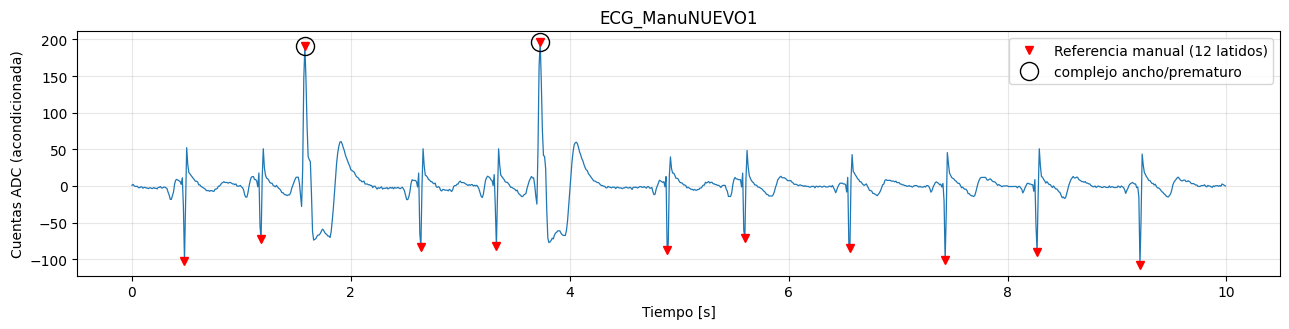

ECG_ManuNUEVO1 - intervalos RR de la referencia [ms]: [ 700  400 1060  690  400 1160  710  960  870  840  940]


In [13]:
def acondicionar(x, fs=FS):
    x = np.asarray(x, dtype=float)
    x = x - np.median(x)
    sos = butter(2, 0.5, btype="highpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

ecg = {n: acondicionar(x) for n, x in señales.items()}

# Latidos anotados a mano (índices de muestra). Incluyen los complejos anchos.
REF = {
    "ECG_ManuNUEVO1": [48, 118, 158, 264, 333, 373, 489, 560, 656, 743, 827, 921],
}

# Subconjunto de la referencia: complejos grandes y anchos que llegan prematuros
REF_ECT = {
    "ECG_ManuNUEVO1": [158, 373],
}

fig, ejes = plt.subplots(len(ecg), 1, figsize=(13, 3.4*len(ecg)), sharex=True, squeeze=False); ejes = ejes[:, 0]
for ax, n in zip(ejes, ecg):
    t = np.arange(len(ecg[n]))/FS
    ax.plot(t, ecg[n], lw=0.9)
    r = np.array(REF[n]); e = np.array(REF_ECT[n])
    ax.plot(r/FS, ecg[n][r], "rv", label=f"Referencia manual ({len(r)} latidos)")
    ax.plot(e/FS, ecg[n][e], "ko", mfc="none", ms=13, label="complejo ancho/prematuro")
    ax.set_title(n); ax.set_ylabel("Cuentas ADC (acondicionada)")
    ax.legend(loc="upper right"); ax.grid(alpha=0.3)
ejes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout(); plt.show()

for n, r in REF.items():
    rr = np.diff(r)/FS*1000
    print(n, "- intervalos RR de la referencia [ms]:", np.round(rr).astype(int))

**5.4.1 Detección de picos R: NeuroKit vs Detectors**

Se comparan 5 métodos de NeuroKit, 5 de Detectors (varios basados en el algoritmo de Pan y Tompkins, 1985) y un detector propio simple como línea base, cada uno con la señal original y con la invertida (la polaridad depende de los electrodos). Métricas: TP (latidos encontrados), FN (perdidos), FP (falsos), sensibilidad, valor predictivo positivo (VPP), F1 y error medio de localización en ms.

In [14]:
# Detectores
def det_neurokit(metodo):
    def f(x, fs):
        _, info = nk.ecg_peaks(x, sampling_rate=fs, method=metodo)
        return np.asarray(info["ECG_R_Peaks"], dtype=int)
    return f

def det_ecgdetectors(nombre):
    def f(x, fs):
        return np.asarray(getattr(Detectors(fs), nombre)(x), dtype=int)
    return f

def det_simple(x, fs):
    """Línea base: energía de la derivada suavizada + umbral + distancia mínima."""
    e = np.diff(x, prepend=x[0])**2
    w = max(1, int(0.08*fs))
    e = np.convolve(e, np.ones(w)/w, mode="same")
    umbral = np.median(e) + 0.15*(e.max()-np.median(e))
    p, _ = find_peaks(e, height=umbral, distance=int(0.25*fs))
    return p

DETECTORES = {("Propio", "derivada^2 + umbral"): det_simple}
if HAY_NK:
    for m in ["neurokit", "pantompkins1985", "hamilton2002", "christov2004", "elgendi2010"]:
        DETECTORES[("NeuroKit", m)] = det_neurokit(m)
if HAY_DET:
    for m in ["pan_tompkins_detector", "hamilton_detector", "christov_detector",
              "engzee_detector", "two_average_detector"]:
        DETECTORES[("Detectors", m)] = det_ecgdetectors(m)

# Evaluación contra la referencia
def evaluar(det, ref, fs=FS, tol_ms=150):
    tol = tol_ms/1000*fs
    det = np.sort(np.asarray(det)); ref = np.asarray(ref)
    usados, tp, errores = set(), 0, []
    for r in ref:
        if len(det) == 0:
            break
        d = np.abs(det - r)
        j = int(np.argmin(d))
        if d[j] <= tol and j not in usados:
            usados.add(j); tp += 1; errores.append((det[j]-r)/fs*1000)
    fn, fp = len(ref)-tp, len(det)-tp
    return {"Detectados": len(det), "TP": tp, "FN": fn, "FP": fp,
            "Sensibilidad": tp/len(ref),
            "VPP": tp/len(det) if len(det) else 0.0,
            "F1": 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else 0.0,
            "Error_abs_medio_ms": float(np.mean(np.abs(errores))) if errores else np.nan}

filas, picos_guardados = [], {}
for reg, x in ecg.items():
    for pol, signo in [("original", 1), ("invertida", -1)]:
        for (lib, met), f in DETECTORES.items():
            try:
                p = f(signo*x, FS)
                m = evaluar(p, REF[reg])
                picos_guardados[(reg, pol, lib, met)] = np.asarray(p)
            except Exception as e:
                m = {"Detectados": np.nan, "TP": np.nan, "FN": np.nan, "FP": np.nan, "Sensibilidad": np.nan,
                     "VPP": np.nan, "F1": np.nan, "Error_abs_medio_ms": np.nan}
                print(f"[{reg} | {pol} | {lib} {met}] falló: {type(e).__name__}: {e}")
            filas.append({"Registro": reg, "Polaridad": pol, "Librería": lib, "Método": met, **m})

resultados = pd.DataFrame(filas)
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 200)
resultados.sort_values(["Registro", "F1"], ascending=[True, False]).round(3)

[ECG_ManuNUEVO1 | original | Detectors engzee_detector] falló: ValueError: Digital filter critical frequencies must be 0 < Wn < 1
[ECG_ManuNUEVO1 | invertida | Detectors engzee_detector] falló: ValueError: Digital filter critical frequencies must be 0 < Wn < 1


,Registro,Polaridad,Librería,Método,Detectados,TP,FN,FP,Sensibilidad,VPP,F1,Error_abs_medio_ms
0,ECG_ManuNUEVO1,original,Propio,derivada^2 + umbral,12.0,12.0,0.0,0.0,1.000,1.000,1.000,9.167
1,ECG_ManuNUEVO1,original,NeuroKit,neurokit,12.0,12.0,0.0,0.0,1.000,1.000,1.000,17.500
2,ECG_ManuNUEVO1,original,NeuroKit,pantompkins1985,12.0,12.0,0.0,0.0,1.000,1.000,1.000,61.667
3,ECG_ManuNUEVO1,original,NeuroKit,hamilton2002,12.0,12.0,0.0,0.0,1.000,1.000,1.000,44.167
6,ECG_ManuNUEVO1,original,Detectors,pan_tompkins_detector,12.0,12.0,0.0,0.0,1.000,1.000,1.000,65.833
7,ECG_ManuNUEVO1,original,Detectors,hamilton_detector,12.0,12.0,0.0,0.0,1.000,1.000,1.000,66.667
10,ECG_ManuNUEVO1,original,Detectors,two_average_detector,12.0,12.0,0.0,0.0,1.000,1.000,1.000,27.500
11,ECG_ManuNUEVO1,invertida,Propio,derivada^2 + umbral,12.0,12.0,0.0,0.0,1.000,1.000,1.000,9.167
12,ECG_ManuNUEVO1,invertida,NeuroKit,neurokit,12.0,12.0,0.0,0.0,1.000,1.000,1.000,5.000
13,ECG_ManuNUEVO1,invertida,NeuroKit,pantompkins1985,12.0,12.0,0.0,0.0,1.000,1.000,1.000,61.667


**Ranking global**

In [15]:
ranking = (resultados.groupby(["Librería", "Método", "Polaridad"], as_index=False)
           [["Sensibilidad", "VPP", "F1", "Error_abs_medio_ms"]].mean()
           .sort_values(["F1", "Error_abs_medio_ms"], ascending=[False, True])
           .reset_index(drop=True))
display(ranking.round(3)) if "display" in globals() else print(ranking.round(3))


candidatos = ranking[ranking["Librería"] != "Propio"]
mejor = (candidatos if len(candidatos) else ranking).iloc[0]
print("\nMejor configuración entre NeuroKit y Detectors (mayor F1 promedio, desempate por menor error de localización):")
print(mejor.to_string())

     Librería                 Método  Polaridad  Sensibilidad    VPP     F1  Error_abs_medio_ms
0    NeuroKit               neurokit  invertida         1.000  1.000  1.000               5.000
1      Propio    derivada^2 + umbral  invertida         1.000  1.000  1.000               9.167
2      Propio    derivada^2 + umbral   original         1.000  1.000  1.000               9.167
3    NeuroKit            elgendi2010  invertida         1.000  1.000  1.000              13.333
4    NeuroKit               neurokit   original         1.000  1.000  1.000              17.500
5   Detectors   two_average_detector   original         1.000  1.000  1.000              27.500
6    NeuroKit           hamilton2002  invertida         1.000  1.000  1.000              44.167
7    NeuroKit           hamilton2002   original         1.000  1.000  1.000              44.167
8   Detectors   two_average_detector  invertida         1.000  1.000  1.000              60.833
9    NeuroKit        pantompkins1985  in

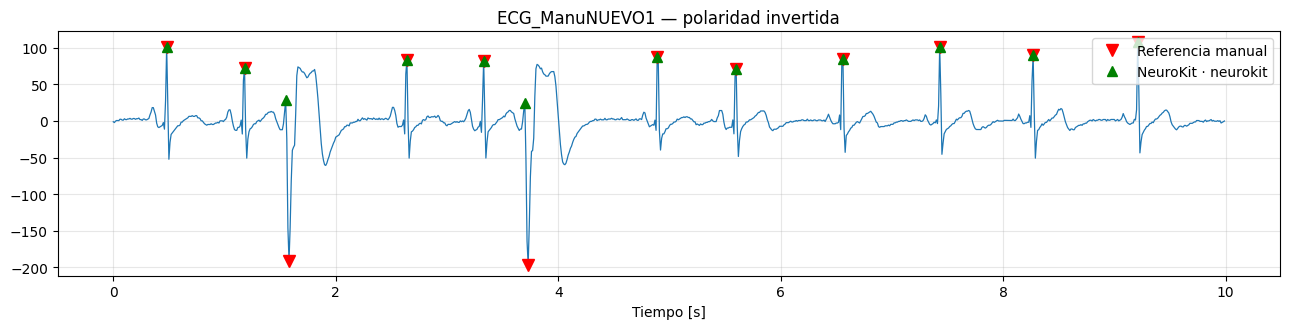

In [16]:
# Detecciones del mejor método sobre cada registro
signo_mejor = 1 if mejor["Polaridad"] == "original" else -1
fig, ejes = plt.subplots(len(ecg), 1, figsize=(13, 3.4*len(ecg)), sharex=True, squeeze=False); ejes = ejes[:, 0]
for ax, reg in zip(ejes, ecg):
    x = signo_mejor*ecg[reg]
    t = np.arange(len(x))/FS
    p = picos_guardados[(reg, mejor["Polaridad"], mejor["Librería"], mejor["Método"])]
    ax.plot(t, x, lw=0.9)
    ax.plot(np.array(REF[reg])/FS, x[REF[reg]], "rv", ms=9, label="Referencia manual")
    ax.plot(p/FS, x[p], "g^", ms=7, label=f"{mejor['Librería']} · {mejor['Método']}")
    ax.set_title(f"{reg} — polaridad {mejor['Polaridad']}")
    ax.legend(loc="upper right"); ax.grid(alpha=0.3)
ejes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout(); plt.show()

In [17]:
# RESPUESTA 5.4.1: ¿cuál detecta mejor los picos R?
print("RESPUESTA 5.4.1")
print(f"Con la anotación manual como referencia, el mejor algoritmo fue "
      f"{mejor['Librería']} - {mejor['Método']} (polaridad {mejor['Polaridad']}): "
      f"sensibilidad {mejor['Sensibilidad']:.2f}, VPP {mejor['VPP']:.2f}, "
      f"F1 {mejor['F1']:.2f} y error medio de localización {mejor['Error_abs_medio_ms']:.1f} ms.\n")
print("Mejor método de cada librería:")
display_df = ranking.drop_duplicates("Librería")[["Librería", "Método", "Polaridad", "Sensibilidad", "VPP", "F1", "Error_abs_medio_ms"]]
print(display_df.round(3).to_string(index=False))

RESPUESTA 5.4.1
Con la anotación manual como referencia, el mejor algoritmo fue NeuroKit - neurokit (polaridad invertida): sensibilidad 1.00, VPP 1.00, F1 1.00 y error medio de localización 5.0 ms.

Mejor método de cada librería:
 Librería               Método Polaridad  Sensibilidad  VPP  F1  Error_abs_medio_ms
 NeuroKit             neurokit invertida           1.0  1.0 1.0               5.000
   Propio  derivada^2 + umbral invertida           1.0  1.0 1.0               9.167
Detectors two_average_detector  original           1.0  1.0 1.0              27.500


**5.4.2 Cálculo de la HRV**

Los intervalos RR (ms) son la diferencia entre picos R consecutivos: `RR[i] = (pico[i+1] − pico[i]) / fs · 1000`, calculados con los picos del mejor método. Como los latidos prematuros generan un intervalo corto seguido de uno largo, se comparan cuatro series: **RR crudo**; **NN Malik (hrvanalysis)**, con `remove_ectopic_beats(method="malik")` e interpolación; **NN criterio del 20 % (manual)**, donde se descartan los intervalos que difieren más del 20 % del anterior y se interpolan; y **NN sin ectópicos por anotación**, donde se descartan los dos intervalos pegados a cada complejo ancho y se interpolan.

0 outlier(s) have been deleted.
4 ectopic beat(s) have been deleted with malik rule.
ECG_ManuNUEVO1: 11 intervalos RR | regla 20 % descarta 7 | anotación de ectópicos descarta 4 (Malik/hrvanalysis: ver mensaje de arriba)


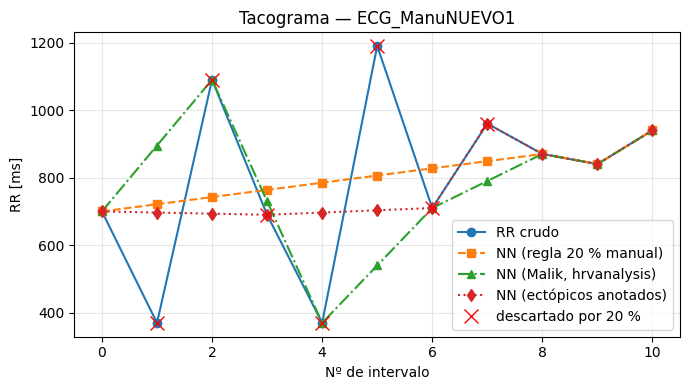

In [18]:
def rr_ms(picos, fs=FS):
    return np.diff(np.sort(picos))/fs*1000.0

def depurar_manual(rr, umbral=0.20):
    """Regla simple del 20 %: marca como ectópico un intervalo que difiere >20% del anterior,
    y rellena por interpolación lineal."""
    rr = np.asarray(rr, dtype=float).copy()
    malos = np.zeros(len(rr), dtype=bool)
    for i in range(1, len(rr)):
        if abs(rr[i]-rr[i-1]) > umbral*rr[i-1]:
            malos[i] = True
    buenos = ~malos
    rr_limpio = np.interp(np.arange(len(rr)), np.where(buenos)[0], rr[buenos])
    return rr_limpio, malos

def depurar_hrvanalysis(rr):
    rr = list(np.asarray(rr, dtype=float))
    rr = remove_outliers(rr_intervals=rr, low_rri=300, high_rri=2000)
    rr = interpolate_nan_values(rr_intervals=rr, interpolation_method="linear")
    rr = remove_ectopic_beats(rr_intervals=rr, method="malik")
    rr = interpolate_nan_values(rr_intervals=rr)
    return np.array([v for v in rr if not np.isnan(v)])

def depurar_por_anotacion(picos, ectopicos, fs=FS, tol_ms=150):
    """Descarta los intervalos RR que tocan un latido anotado como ancho/prematuro
    (el intervalo corto que llega a él y la pausa que le sigue) e interpola."""
    picos = np.sort(np.asarray(picos)); tol = tol_ms/1000*fs
    es_ect = np.array([np.any(np.abs(ectopicos - p) <= tol) for p in picos])
    rr = rr_ms(picos)
    malos = es_ect[:-1] | es_ect[1:]            # intervalo i va del pico i al pico i+1
    buenos = ~malos
    return np.interp(np.arange(len(rr)), np.where(buenos)[0], rr[buenos]), malos

serie_rr = {}
for reg in ecg:
    p = picos_guardados[(reg, mejor["Polaridad"], mejor["Librería"], mejor["Método"])]
    crudo = rr_ms(p)
    nn_manual, malos = depurar_manual(crudo)
    nn_lib = depurar_hrvanalysis(crudo) if HAY_HRV else None
    nn_anot, malos_anot = depurar_por_anotacion(p, np.array(REF_ECT[reg]))
    serie_rr[reg] = {"crudo": crudo, "nn_manual": nn_manual, "nn_lib": nn_lib,
                     "malos": malos, "nn_anot": nn_anot, "malos_anot": malos_anot}
    print(f"{reg}: {len(crudo)} intervalos RR | regla 20 % descarta {malos.sum()} | "
          f"anotación de ectópicos descarta {malos_anot.sum()} (Malik/hrvanalysis: ver mensaje de arriba)")

fig, ejes = plt.subplots(1, len(serie_rr), figsize=(7*len(serie_rr), 4), squeeze=False); ejes = ejes[0]
for ax, reg in zip(ejes, serie_rr):
    s = serie_rr[reg]
    ax.plot(s["crudo"], "o-", label="RR crudo")
    ax.plot(s["nn_manual"], "s--", label="NN (regla 20 % manual)")
    if s["nn_lib"] is not None:
        ax.plot(s["nn_lib"], "^-.", label="NN (Malik, hrvanalysis)")
    ax.plot(s["nn_anot"], "d:", label="NN (ectópicos anotados)")
    ax.plot(np.where(s["malos"])[0], s["crudo"][s["malos"]], "rx", ms=10, label="descartado por 20 %")
    ax.set_title(f"Tacograma — {reg}"); ax.set_xlabel("Nº de intervalo"); ax.set_ylabel("RR [ms]")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**5.4.3 Características de HRV en el dominio del tiempo (`get_time_domain_features`)**

La función recibe los intervalos en ms y devuelve, entre otras: `mean_nni` (RR medio), `mean_hr` (frecuencia cardíaca media), `sdnn` (desviación estándar de los intervalos, variabilidad total), `rmssd` (raíz cuadrática media de las diferencias sucesivas, variabilidad latido a latido), `sdsd`, `nni_50` y `pnni_50` (diferencias sucesivas > 50 ms). Se calculan también de forma manual como verificación.

In [19]:
def hrv_tiempo_manual(rr):
    rr = np.asarray(rr, dtype=float); d = np.diff(rr)
    return {"mean_nni": rr.mean(), "sdnn": rr.std(ddof=1),
            "rmssd": np.sqrt(np.mean(d**2)), "sdsd": d.std(ddof=0),
            "nni_50": int(np.sum(np.abs(d) > 50)),
            "pnni_50": 100*np.mean(np.abs(d) > 50),
            "median_nni": np.median(rr), "range_nni": rr.max()-rr.min(),
            "mean_hr": np.mean(60000/rr)}

tablas = []
for reg, s in serie_rr.items():
    versiones = {"RR crudo": s["crudo"],
                 "NN criterio 20 % (manual)": s["nn_manual"],
                 "NN sin ectópicos (anotación)": s["nn_anot"]}
    if HAY_HRV:
        versiones["NN Malik (hrvanalysis)"] = s["nn_lib"]
    for etiqueta, serie in versiones.items():
        if HAY_HRV:
            tablas.append({"Registro": reg, "Serie": etiqueta, "Origen": "hrvanalysis",
                           **get_time_domain_features(list(serie))})
        tablas.append({"Registro": reg, "Serie": etiqueta, "Origen": "manual",
                       **hrv_tiempo_manual(serie)})

tabla_hrv = pd.DataFrame(tablas)
cols = ["Registro", "Serie", "Origen", "mean_nni", "mean_hr", "sdnn", "rmssd", "sdsd", "nni_50", "pnni_50"]
tabla_hrv[[c for c in cols if c in tabla_hrv.columns]].round(2)

,Registro,Serie,Origen,mean_nni,mean_hr,sdnn,rmssd,sdsd,nni_50,pnni_50
0,ECG_ManuNUEVO1,RR crudo,hrvanalysis,793.64,86.70,262.19,432.90,432.23,9,90.0
1,ECG_ManuNUEVO1,RR crudo,manual,793.64,86.70,262.19,432.90,432.23,9,90.0
2,ECG_ManuNUEVO1,NN criterio 20 % (manual),hrvanalysis,804.09,75.14,70.81,38.10,29.58,1,10.0
3,ECG_ManuNUEVO1,NN criterio 20 % (manual),manual,804.09,75.14,70.81,38.10,29.58,1,10.0
4,ECG_ManuNUEVO1,NN sin ectópicos (anotación),hrvanalysis,772.73,78.91,107.61,90.37,87.12,3,30.0
5,ECG_ManuNUEVO1,NN sin ectópicos (anotación),manual,772.73,78.91,107.61,90.37,87.12,3,30.0
6,ECG_ManuNUEVO1,NN Malik (hrvanalysis),hrvanalysis,770.45,84.36,196.27,204.14,202.73,9,90.0
7,ECG_ManuNUEVO1,NN Malik (hrvanalysis),manual,770.45,84.36,196.27,204.14,202.73,9,90.0


In [20]:
# Resumen automático: efecto de los latidos prematuros sobre la HRV
t = tabla_hrv[tabla_hrv["Origen"] == ("hrvanalysis" if HAY_HRV else "manual")].set_index("Serie")
crudo, anot = t.loc["RR crudo"], t.loc["NN sin ectópicos (anotación)"]
print("RESUMEN 5.4.3")
print(f"RMSSD: {crudo['rmssd']:.0f} ms (RR crudo) vs {anot['rmssd']:.0f} ms (sin ectópicos).")
print(f"SDNN:  {crudo['sdnn']:.0f} ms (RR crudo) vs {anot['sdnn']:.0f} ms (sin ectópicos).")
print(f"Frecuencia cardíaca media: {crudo['mean_hr']:.0f} lpm (crudo) vs {anot['mean_hr']:.0f} lpm (sin ectópicos).")

RESUMEN 5.4.3
RMSSD: 433 ms (RR crudo) vs 90 ms (sin ectópicos).
SDNN:  262 ms (RR crudo) vs 108 ms (sin ectópicos).
Frecuencia cardíaca media: 87 lpm (crudo) vs 79 lpm (sin ectópicos).


**Análisis del 5.4**

El algoritmo que mejor detectó los picos R en este registro fue el método `neurokit` de NeuroKit con la señal invertida (sensibilidad, VPP y F1 de 1.0, y error medio de localización de 5.0 ms). La mayoría de los métodos detectó los 12 latidos sin falsos positivos, por lo que el desempate fue el error de localización; los métodos de Christov perdieron un latido y generaron un falso positivo, `elgendi2010` con la señal original produjo 3 falsos positivos y `engzee_detector` no pudo ejecutarse, porque su filtro interno requiere una frecuencia de corte por encima del límite de Nyquist con fs = 100 Hz. El error de localización depende además del punto del QRS tomado como referencia (aquí, el mínimo del complejo), por lo que el resultado es ilustrativo y no concluyente, al basarse en solo 12 latidos anotados a mano.

En el cálculo de la HRV dominan dos complejos anchos que llegan antes de tiempo (RR de ≈ 400 ms frente a ≈ 700 ms en los latidos normales) y van seguidos de una pausa más larga. Es un patrón compatible con latidos prematuros, no un diagnóstico. Con los RR crudos el RMSSD fue de ≈ 433 ms y el SDNN de ≈ 262 ms; al descartar los intervalos asociados a esos latidos (depuración por anotación) bajaron a ≈ 90 ms y ≈ 108 ms. Por tanto, la mayor parte de la variabilidad cruda no refleja la modulación sinusal que mide la HRV y depurar la serie es indispensable. El resultado depende también del criterio: `remove_ectopic_beats(method="malik")` de hrvanalysis eliminó 4 intervalos y dejó un RMSSD de ≈ 204 ms, la depuración por anotación eliminó otros 4 y dejó ≈ 90 ms, y la regla manual del 20 % eliminó 7 de los 11 intervalos y dejó un RMSSD de ≈ 38 ms; como esta última reemplaza por interpolación más de la mitad de la serie, su valor es poco fiable. Es decir, el RMSSD varía entre ≈ 38 y ≈ 204 ms según el criterio (frente a ≈ 433 ms en el registro crudo), y con tan pocos latidos el índice depende de las decisiones de preprocesamiento.

Los resultados son orientativos y no robustos: el registro dura ≈ 10 s (los estándares de HRV a corto plazo usan 5 min; Task Force, 1996), la frecuencia de muestreo es ≈ 100 Hz y no está controlada por un temporizador de hardware, y se trata de un solo registro de una persona.

**5.5 APLICACIONES CLÍNICAS DEL ECG Y DEL EMG**

| Señal | Aplicación clínica | Tipo de registro | Procesamiento |
|---|---|---|---|
| ECG | **Detección y clasificación de arritmias** (por ejemplo, fibrilación auricular) | ECG ambulatorio (Holter o parche de una derivación, de horas a días) o ECG de 12 derivaciones en reposo | Filtrado de ruido y línea base, detección de picos R, análisis de intervalos RR e irregularidad, extracción de características o redes neuronales profundas (Hannun et al., 2019) |
| ECG | **Diagnóstico de isquemia e infarto de miocardio** | ECG de 12 derivaciones en reposo y, en ocasiones, de esfuerzo | Filtrado, detección de latidos y puntos fiduciales, medición del desnivel del segmento ST y de la onda T y Q (Thygesen et al., 2019) |
| ECG | **Evaluación de la HRV y de la función autonómica** (estratificación de riesgo) | ECG en reposo de corta duración (≈ 5 min) o de larga duración (24 h) | Detección de R, depuración de latidos ectópicos, métricas en el dominio del tiempo (SDNN, RMSSD) y de la frecuencia (LF/HF) (Task Force, 1996) |
| EMG | **Diagnóstico de enfermedades neuromusculares** (neuropatías, miopatías, ELA) | EMG de aguja intramuscular, en reposo y con contracción leve a máxima, junto con estudios de conducción nerviosa | Análisis de potenciales de unidad motora (amplitud, duración, número de fases), actividad espontánea y patrón de reclutamiento (Mills, 2005) |
| EMG | **Control de prótesis mioeléctricas** | sEMG de los músculos residuales del antebrazo o del muñón | Filtrado y rectificación, ventaneo, características (MAV, RMS, longitud de onda, cruces por cero) y clasificador de movimientos (Farina et al., 2014) |
| EMG | **Evaluación de fatiga muscular, ergonomía y rehabilitación** | sEMG durante contracciones sostenidas o dinámicas | Amplitud RMS y análisis espectral en el tiempo (la frecuencia mediana disminuye con la fatiga) (Cifrek et al., 2009) |

**5.6 CONCLUSIONES**

1. Las bioseñales tienen amplitudes de microvoltios a milivoltios, por lo que la interfaz piel-electrodo y el control de las fuentes de ruido (red eléctrica, movimiento, deriva de línea base) condicionan todo el procesamiento posterior. Una impedancia de contacto alta o desbalanceada reduce el rechazo de modo común del amplificador y deja pasar la interferencia, y lo que entra contaminado no se recupera por completo con filtrado digital. Por eso la preparación de la piel y la fijación de los electrodos son tan importantes como el análisis posterior.

2. La frecuencia de muestreo (≈ 100 Hz) y la corta duración del registro (≈ 10 s) restringen el análisis de HRV: cada pico R tiene una incertidumbre de ±10 ms, comparable con los valores pequeños de RMSSD, y con ≈ 12 latidos las métricas son orientativas. Los estándares clínicos recomiendan al menos 5 min de registro (Task Force, 1996), y una frecuencia de muestreo más alta con temporizador de hardware permitiría localizar mejor los picos.

3. Los complejos anchos que llegan antes de tiempo, seguidos de una pausa más larga, inflan métricas como sdnn y rmssd, de modo que la variabilidad de la serie cruda refleja esos latidos y no la modulación sinusal. Por eso es necesario depurar los latidos ectópicos antes de interpretar la HRV, y el resultado depende del criterio de depuración elegido (Malik, regla del 20 % o anotación), sobre todo cuando hay pocos latidos.

4. La comparación entre NeuroKit (Makowski et al., 2021) y Detectors, con métodos como el de Pan y Tompkins (1985), se hizo contra una referencia anotada a mano y con métricas cuantitativas (sensibilidad, VPP, F1 y error de localización), y no solo por inspección visual. El mejor desempeño lo obtuvo el método `neurokit` de NeuroKit sobre la señal invertida, que detectó los 12 latidos sin falsos positivos y con el menor error de localización (≈ 5 ms). Como se basa en solo 12 latidos, el resultado es ilustrativo y no permite generalizar que un algoritmo sea mejor que otro.

**REFERENCIAS**

- Cifrek, M., Medved, V., Tonković, S., & Ostojić, S. (2009). Surface EMG based muscle fatigue evaluation in biomechanics. *Clinical Biomechanics, 24*(4), 327–340. https://doi.org/10.1016/j.clinbiomech.2009.01.010
- Farina, D., Jiang, N., Rehbaum, H., Holobar, A., Graimann, B., Dietl, H., & Aszmann, O. C. (2014). The extraction of neural information from the surface EMG for the control of upper-limb prostheses: Emerging avenues and challenges. *IEEE Transactions on Neural Systems and Rehabilitation Engineering, 22*(4), 797–809.
- Hannun, A. Y., Rajpurkar, P., Haghpanahi, M., et al. (2019). Cardiologist-level arrhythmia detection and classification in ambulatory electrocardiograms using a deep neural network. *Nature Medicine, 25*(1), 65–69.
- Huigen, E., Peper, A., & Grimbergen, C. A. (2002). Investigation into the origin of the noise of surface electrodes. *Medical & Biological Engineering & Computing, 40*, 332–338. https://doi.org/10.1007/BF02344216
- Makowski, D., Pham, T., Lau, Z. J., Brammer, J. C., Lespinasse, F., Pham, H., Schölzel, C., & Chen, S. H. A. (2021). NeuroKit2: A Python toolbox for neurophysiological signal processing. *Behavior Research Methods, 53*(4), 1689–1696. https://doi.org/10.3758/s13428-020-01516-y
- Mills, K. R. (2005). The basics of electromyography. *Journal of Neurology, Neurosurgery & Psychiatry, 76*(Suppl 2), ii32–ii35.
- Pan, J., & Tompkins, W. J. (1985). A real-time QRS detection algorithm. *IEEE Transactions on Biomedical Engineering, 32*(3), 230–236.
- Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology. (1996). Heart rate variability: Standards of measurement, physiological interpretation, and clinical use. *Circulation, 93*(5), 1043–1065.
- Thygesen, K., Alpert, J. S., Jaffe, A. S., et al. (2019). Fourth universal definition of myocardial infarction (2018). *European Heart Journal, 40*(3), 237–269.
- Webster, J. G. (Ed.). (2009). *Medical instrumentation: Application and design* (4th ed.). John Wiley & Sons.